In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("Data_Science.xlsx")

display(df.head())

print("Dataset shape:", df.shape)

df.info()

print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

,Transaction_ID,Customer_Name,City,Department,Product,Quantity,Unit_Price,Revenue,Expense,Profit,Customer_Rating,Customer_Feedback,Employee_Performance_Score,Payment_Method,Purchase_Date
0,TXN00001,Maria Dominguez,Hyderabad,HR,Headphones,2,69623,139246,79676,59570,1,Poor,98,Net Banking,2024-10-23
1,TXN00002,Jasmine Wells,Mumbai,Sales,Keyboard,3,5478,16434,7198,9236,4,Excellent,53,Net Banking,2024-06-04
2,TXN00003,Sherri Brown,Delhi,Finance,Tablet,8,2629,21032,12831,8201,2,Average,76,Net Banking,2024-11-22
3,TXN00004,Dr. Lisa Garcia,Mumbai,IT,Mobile,5,49088,245440,131238,114202,2,Good,86,Card,2024-03-28
4,TXN00005,Kelly Carpenter,Delhi,IT,Smartwatch,10,17066,170660,104544,66116,4,Poor,90,UPI,2024-02-06


Dataset shape: (8000, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Transaction_ID              8000 non-null   object
 1   Customer_Name               8000 non-null   object
 2   City                        8000 non-null   object
 3   Department                  8000 non-null   object
 4   Product                     8000 non-null   object
 5   Quantity                    8000 non-null   int64 
 6   Unit_Price                  8000 non-null   int64 
 7   Revenue                     8000 non-null   int64 
 8   Expense                     8000 non-null   int64 
 9   Profit                      8000 non-null   int64 
 10  Customer_Rating             8000 non-null   int64 
 11  Customer_Feedback           8000 non-null   object
 12  Employee_Performance_Score  8000 non-null   int64 
 13  Payment_Method        

In [ ]:
df["Purchase_Date"] = pd.to_datetime(
    df["Purchase_Date"],
    errors="coerce"
)

# Reference date: one day after the latest purchase
reference_date = df["Purchase_Date"].max() + pd.Timedelta(days=1)

print("Reference date:", reference_date)

Reference date: 2025-05-16 00:00:00


In [ ]:
customer_df = df.groupby("Customer_Name").agg(
    Total_Spending=("Revenue", "sum"),
    Total_Profit=("Profit", "sum"),
    Purchase_Frequency=("Transaction_ID", "nunique"),
    Total_Quantity=("Quantity", "sum"),
    Average_Order_Value=("Revenue", "mean"),
    Average_Rating=("Customer_Rating", "mean"),
    Last_Purchase=("Purchase_Date", "max")
).reset_index()

# Calculate recency
customer_df["Recency"] = (
    reference_date - customer_df["Last_Purchase"]
).dt.days

# Display customer-level data
display(customer_df.head())

print("Customer-level shape:", customer_df.shape)

,Customer_Name,Total_Spending,Total_Profit,Purchase_Frequency,Total_Quantity,Average_Order_Value,Average_Rating,Last_Purchase,Recency
0,Aaron Adams,106710,31794,1,5,106710.0,2.0,2024-07-22,298
1,Aaron Adams DDS,22240,12493,1,5,22240.0,4.0,2025-04-13,33
2,Aaron Bell,149746,73868,1,2,149746.0,1.0,2024-11-08,189
3,Aaron Benton,28292,10653,1,4,28292.0,3.0,2025-02-13,92
4,Aaron Brown,6697,1550,1,1,6697.0,5.0,2024-11-15,182


Customer-level shape: (7612, 9)


,Total_Spending,Total_Profit,Purchase_Frequency,Total_Quantity,Average_Order_Value,Average_Rating,Last_Purchase,Recency
count,7.612000e+03,7612.000000,7612.000000,7612.000000,7612.000000,7612.000000,7612,7612.000000
mean,2.318231e+05,80900.320678,1.050972,5.769706,220729.576798,2.972051,2024-09-11 01:10:11.035207680,246.951261
min,5.560000e+02,180.000000,1.000000,1.000000,556.000000,1.000000,2024-01-01 00:00:00,1.000000
25%,7.022550e+04,21367.250000,1.000000,3.000000,69455.000000,2.000000,2024-05-08 00:00:00,120.750000
50%,1.738700e+05,53865.500000,1.000000,6.000000,168379.500000,3.000000,2024-09-13 00:00:00,245.000000
75%,3.515922e+05,114122.000000,1.000000,8.000000,334200.000000,4.000000,2025-01-15 06:00:00,373.000000
max,1.769140e+06,643382.000000,6.000000,35.000000,798410.000000,5.000000,2025-05-15 00:00:00,501.000000
std,1.969033e+05,80897.915849,0.259423,3.246564,182202.327450,1.387326,NaN,145.257293


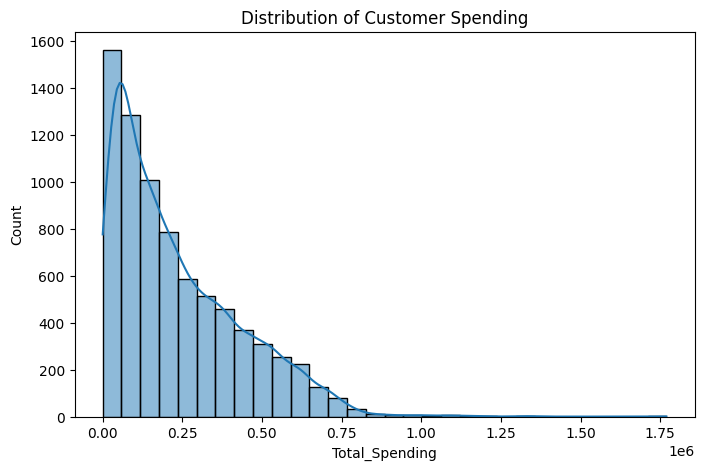

In [ ]:
# Statistical summary
display(customer_df.describe())

# Distribution of customer spending
plt.figure(figsize=(8, 5))
sns.histplot(
    data=customer_df,
    x="Total_Spending",
    bins=30,
    kde=True
)
plt.title("Distribution of Customer Spending")
plt.show()

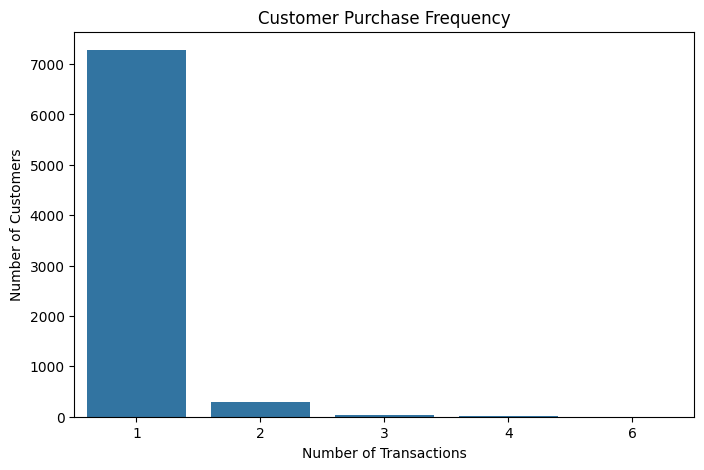

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=customer_df,
    x="Purchase_Frequency"
)

plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Transactions")
plt.ylabel("Number of Customers")
plt.show()

In [ ]:
features = [
    "Total_Spending",
    "Total_Profit",
    "Purchase_Frequency",
    "Average_Order_Value",
    "Recency"
]

X = customer_df[features].copy()

print(X.head())
print(X.shape)

   Total_Spending  Total_Profit  Purchase_Frequency  Average_Order_Value  \
0          106710         31794                   1             106710.0   
1           22240         12493                   1              22240.0   
2          149746         73868                   1             149746.0   
3           28292         10653                   1              28292.0   
4            6697          1550                   1               6697.0   

   Recency  
0      298  
1       33  
2      189  
3       92  
4      182  
(7612, 5)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (7612, 5)


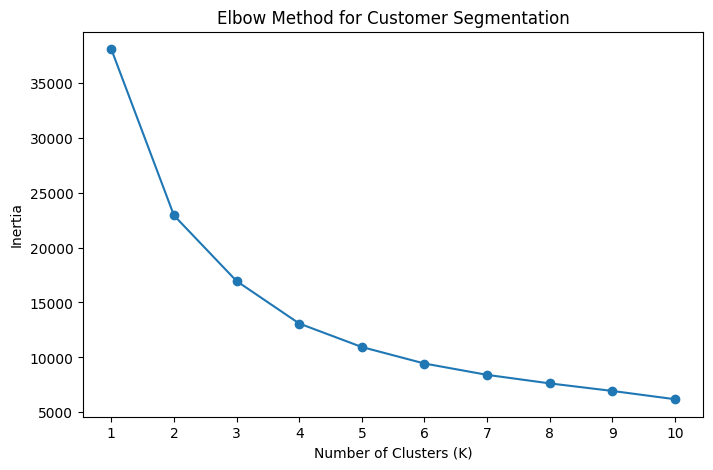

In [ ]:
from sklearn.cluster import KMeans

inertia = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Segmentation")
plt.xticks(list(k_values))
plt.show()

In [ ]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

customer_df["Cluster"] = kmeans.fit_predict(X_scaled)

display(customer_df.head())

print(customer_df["Cluster"].value_counts().sort_index())

,Customer_Name,Total_Spending,Total_Profit,Purchase_Frequency,Total_Quantity,Average_Order_Value,Average_Rating,Last_Purchase,Recency,Cluster
0,Aaron Adams,106710,31794,1,5,106710.0,2.0,2024-07-22,298,2
1,Aaron Adams DDS,22240,12493,1,5,22240.0,4.0,2025-04-13,33,1
2,Aaron Bell,149746,73868,1,2,149746.0,1.0,2024-11-08,189,1
3,Aaron Benton,28292,10653,1,4,28292.0,3.0,2025-02-13,92,1
4,Aaron Brown,6697,1550,1,1,6697.0,5.0,2024-11-15,182,1


Cluster
0     334
1    2639
2    2696
3    1943
Name: count, dtype: int64


In [ ]:
cluster_summary = customer_df.groupby("Cluster").agg(
    Customer_Count=("Customer_Name", "count"),
    Avg_Spending=("Total_Spending", "mean"),
    Avg_Profit=("Total_Profit", "mean"),
    Avg_Purchase_Frequency=("Purchase_Frequency", "mean"),
    Avg_Order_Value=("Average_Order_Value", "mean"),
    Avg_Recency=("Recency", "mean")
).round(2)

display(cluster_summary)

,Customer_Count,Avg_Spending,Avg_Profit,Avg_Purchase_Frequency,Avg_Order_Value,Avg_Recency
Cluster,,,,,,
0,334,473439.48,166797.20,2.16,220613.63,165.61
1,2639,128040.72,42445.81,1.00,128040.72,123.60
2,2696,125830.30,42057.63,1.00,125830.30,376.01
3,1943,478317.37,172259.97,1.00,478317.37,249.39


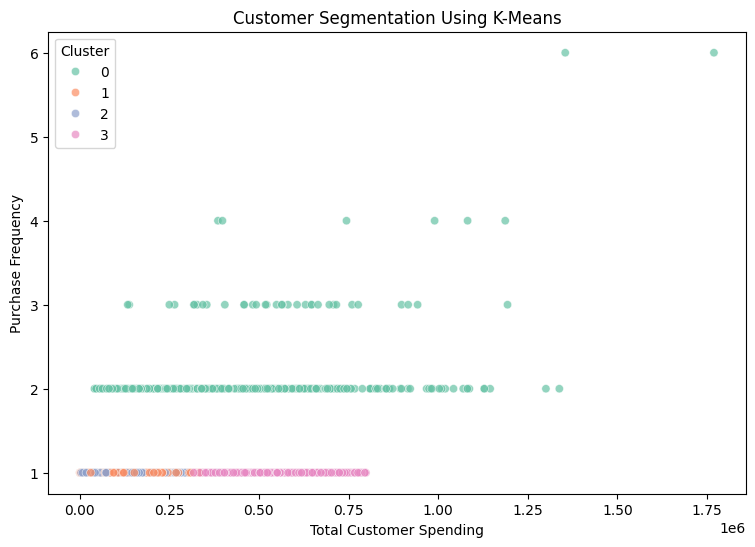

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=customer_df,
    x="Total_Spending",
    y="Purchase_Frequency",
    hue="Cluster",
    palette="Set2",
    alpha=0.7
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Total Customer Spending")
plt.ylabel("Purchase Frequency")
plt.show()

In [9]:
customer_df.to_excel(
    "Customer_Segmentation_Results.xlsx",
    index=False
)

print("Customer segmentation results exported successfully.")

Customer segmentation results exported successfully.
